# Εργασία 5 – Δέντρα Απόφασης: Πρόβλεψη Πόσιμου Νερού


In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, classification_report, fbeta_score)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 250)
plt.rcParams["figure.dpi"] = 100
SEED = 0

In [48]:
!pip install -q dtreeviz

## Ερώτημα 1 – Φόρτωση δεδομένων και διερεύνηση

In [49]:
df = pd.read_csv("water_potability.csv")
print("Διαστάσεις:", df.shape)
df.head()

Διαστάσεις: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


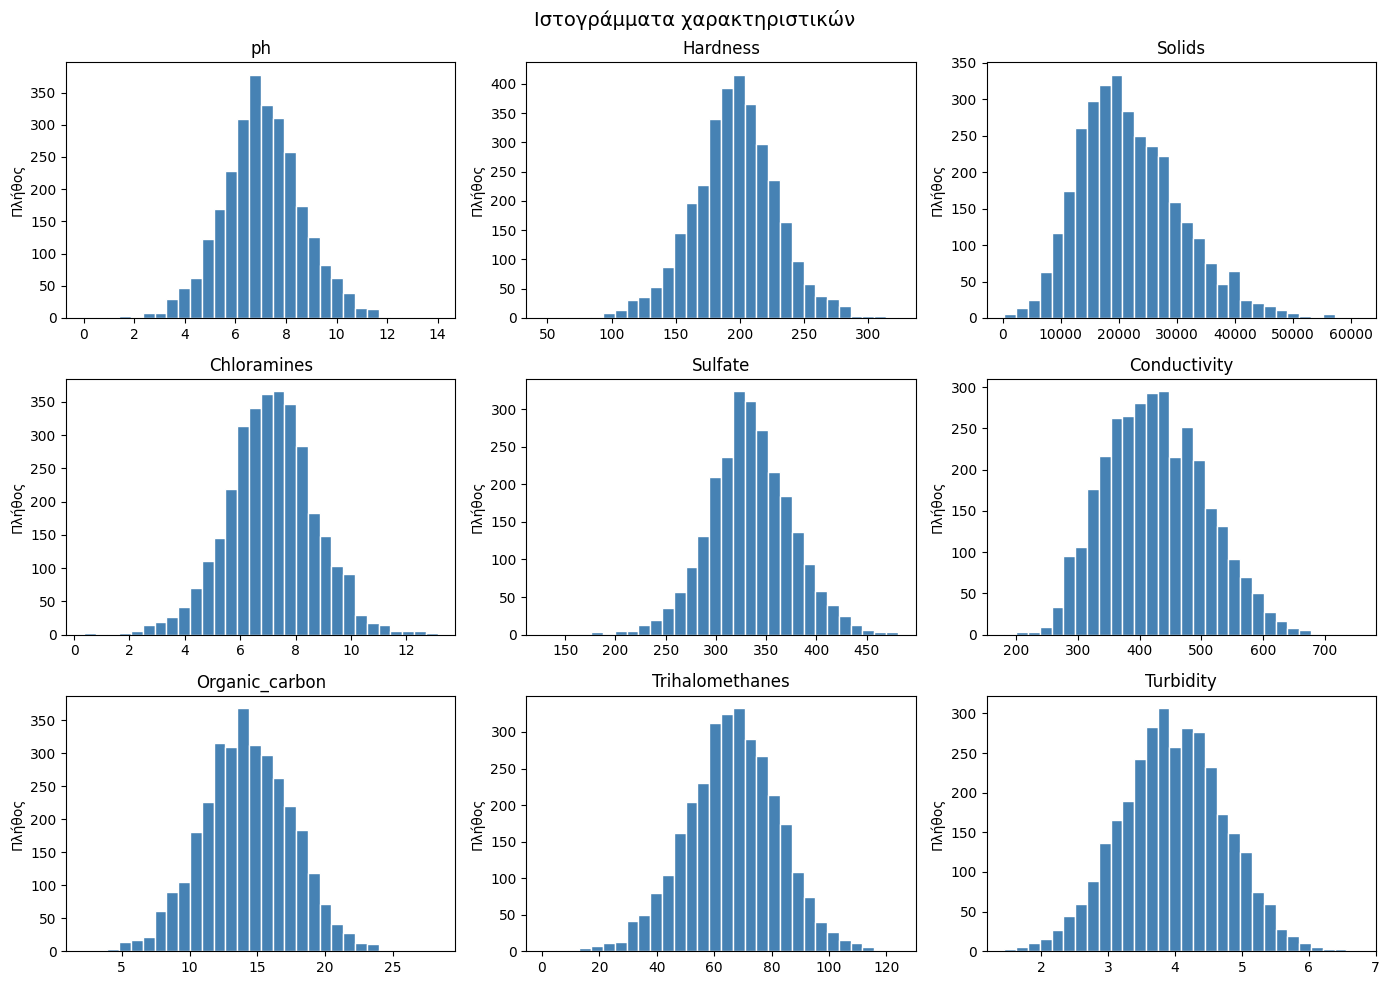

In [50]:
features = [c for c in df.columns if c != "Potability"]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col].dropna(), bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Πλήθος")
fig.suptitle("Ιστογράμματα χαρακτηριστικών", fontsize=14)
plt.tight_layout()
plt.show()

Παρατηρήσεις: σχεδόν όλα τα χαρακτηριστικά (ph, Hardness, Chloramines, Sulfate, Organic_carbon, Trihalomethanes, Turbidity) έχουν περίπου κανονική (καμπανοειδή) κατανομή γύρω από τη μέση τιμή τους (π.χ. pH ≈ 7, Chloramines ≈ 7 ppm). Το Solids είναι ασύμμετρο προς τα δεξιά με ουρά προς υψηλές τιμές, και το Conductivity ελαφρώς. Δεν φαίνεται κάποιο χαρακτηριστικό να έχει δύο ξεχωριστές «κορυφές» που θα έδειχναν φυσικό διαχωρισμό πόσιμου/μη πόσιμου.

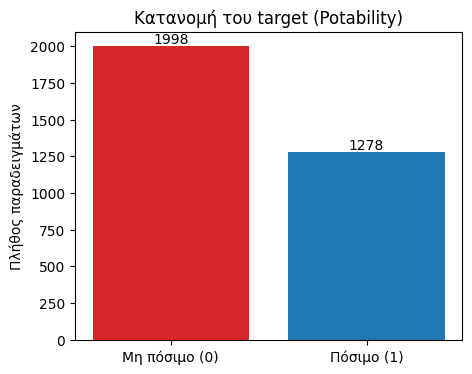

Μη πόσιμο: 1998 (60.99%)
Πόσιμο:    1278 (39.01%)


In [51]:
counts = df["Potability"].value_counts().sort_index()
labels = ["Μη πόσιμο (0)", "Πόσιμο (1)"]

plt.figure(figsize=(5, 4))
bars = plt.bar(labels, counts.values, color=["tab:red", "tab:blue"])
plt.bar_label(bars)
plt.title("Κατανομή του target (Potability)")
plt.ylabel("Πλήθος παραδειγμάτων")
plt.show()

pct = (df["Potability"].value_counts(normalize=True).sort_index() * 100).round(2)
print(f"Μη πόσιμο: {counts[0]} ({pct[0]}%)")
print(f"Πόσιμο:    {counts[1]} ({pct[1]}%)")

In [52]:
missing = pd.DataFrame({
    "Ελλιπείς τιμές": df.isna().sum(),
    "Ποσοστό (%)": (df.isna().mean() * 100).round(2)})
missing[missing["Ελλιπείς τιμές"] > 0]

,Ελλιπείς τιμές,Ποσοστό (%)
ph,491,14.99
Sulfate,781,23.84
Trihalomethanes,162,4.95


Ελλιπείς τιμές: τρία χαρακτηριστικά έχουν κενά: Sulfate (781, 23.8%), ph (491, 15.0%) και Trihalomethanes (162, 4.9%). Τα υπόλοιπα είναι πλήρη.

Targets: 60.99% μη πόσιμο (1998) και 39.01% πόσιμο (1278). Το σύνολο είναι μέτρια μη ισορροπημένο. Ένας ταξινομητής που απαντά πάντα «μη πόσιμο» θα είχε ήδη ~61% accuracy, και αυτό είναι το baseline με το οποίο πρέπει να συγκρίνουμε όλα τα μοντέλα παρακάτω.

## Ερώτημα 2 – Οδηγία ΠΟΥ για το pH

In [53]:
ph_groups = {
    "α) pH < 6.5":         df["ph"] < 6.5,
    "β) 6.5 ≤ pH ≤ 8.5":  (df["ph"] >= 6.5) & (df["ph"] <= 8.5),
    "γ) pH > 8.5":         df["ph"] > 8.5,
}
rows = []
for name, mask in ph_groups.items():
    sub = df[mask]
    rows.append({"Κατηγορία": name, "Παραδείγματα": len(sub),
                 "% πόσιμο": round(100 * (sub["Potability"] == 1).mean(), 2),
                 "% μη πόσιμο": round(100 * (sub["Potability"] == 0).mean(), 2)})
ph_table = pd.DataFrame(rows).set_index("Κατηγορία")
print(f"(Εξαιρούνται {df['ph'].isna().sum()} παραδείγματα χωρίς τιμή pH)")
ph_table

(Εξαιρούνται 491 παραδείγματα χωρίς τιμή pH)


,Παραδείγματα,% πόσιμο,% μη πόσιμο
Κατηγορία,,,
α) pH < 6.5,968,36.78,63.22
β) 6.5 ≤ pH ≤ 8.5,1328,43.90,56.10
γ) pH > 8.5,489,33.13,66.87


Το μη πόσιμο υπερτερεί σε όλες τις κατηγορίες. Η ιδιότητα επαληθεύεται μόνο ασθενώς:

- Στο προτεινόμενο εύρος 6.5–8.5 το ποσοστό πόσιμου είναι το υψηλότερο (43.9%), ενώ εκτός εύρους είναι χαμηλότερο (36.8% για pH < 6.5 και 33.1% για pH > 8.5). Η κατεύθυνση είναι σωστή.
- Όμως η διαφορά είναι μικρή (~7–11 ποσοστιαίες μονάδες), και ακόμη και μέσα στο «σωστό» εύρος το 56% των δειγμάτων είναι μη πόσιμα, ενώ περίπου 1 στα 3 δείγματα με pH εκτός ορίων είναι πόσιμο. Άρα το pH από μόνο του δεν αρκεί για να αποφασίσουμε.

## Ερώτημα 3 – Διάγραμμα διασποράς pH – Chloramines

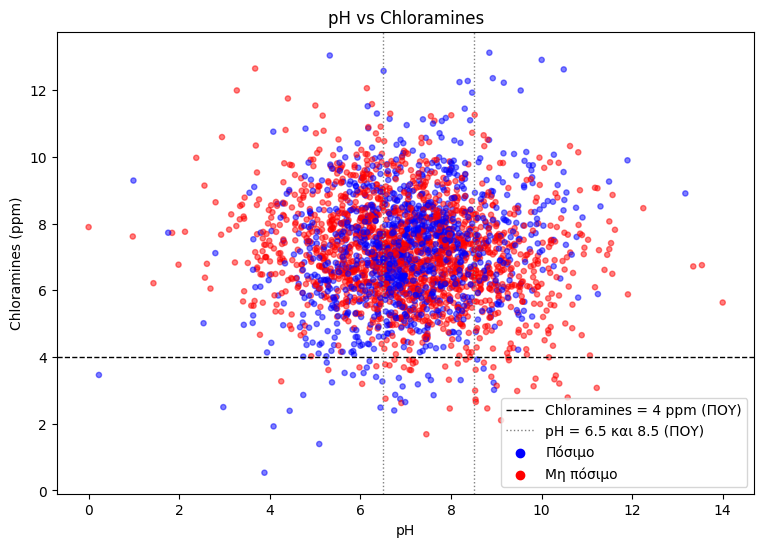

Ποσοστό πόσιμου με Chloramines ≤ 4: 40.4%
Ποσοστό πόσιμου με Chloramines  > 4: 39.0%
Ποσοστό δειγμάτων με Chloramines > 4: 97.3%


In [54]:
plot_df = df.dropna(subset=["ph"])
colors = plot_df["Potability"].map({1: "blue", 0: "red"})

plt.figure(figsize=(9, 6))
plt.scatter(plot_df["ph"], plot_df["Chloramines"], c=colors, s=14, alpha=0.5)
plt.axhline(4, color="k", ls="--", lw=1, label="Chloramines = 4 ppm (ΠΟΥ)")
plt.axvline(6.5, color="gray", ls=":", lw=1)
plt.axvline(8.5, color="gray", ls=":", lw=1, label="pH = 6.5 και 8.5 (ΠΟΥ)")
plt.scatter([], [], c="blue", label="Πόσιμο"); plt.scatter([], [], c="red", label="Μη πόσιμο")
plt.xlabel("pH"); plt.ylabel("Chloramines (ppm)")
plt.title("pH vs Chloramines")
plt.legend()
plt.show()

print("Ποσοστό πόσιμου με Chloramines ≤ 4: %.1f%%" % (100 * df.loc[df.Chloramines <= 4, "Potability"].mean()))
print("Ποσοστό πόσιμου με Chloramines  > 4: %.1f%%" % (100 * df.loc[df.Chloramines > 4, "Potability"].mean()))
print("Ποσοστό δειγμάτων με Chloramines > 4: %.1f%%" % (100 * (df.Chloramines > 4).mean()))

Τα μπλε (πόσιμα) και τα κόκκινα (μη πόσιμα) σημεία είναι πλήρως αναμεμειγμένα σε ένα ενιαίο σύννεφο γύρω από pH ≈ 7 και Chloramines ≈ 7 ppm. Δεν υπάρχει περιοχή που να κυριαρχεί το ένα χρώμα, ούτε ευθεία ή ορθογώνιο όριο που να τα χωρίζει, άρα τα δεδομένα δεν είναι διαχωρίσιμα με αυτά τα δύο χαρακτηριστικά.

Το όριο των 4 ppm του ΠΟΥ δεν βοηθά: το 97.3% των δειγμάτων το υπερβαίνει, και το ποσοστό πόσιμου είναι σχεδόν ίδιο πάνω και κάτω από αυτό (39.0% έναντι 40.4%). Θα περιμέναμε το νερό πάνω από 4 ppm να είναι μη πόσιμο, αλλά τα δεδομένα δεν το δείχνουν. Αυτό προϊδεάζει ότι η πρόβλεψη θα είναι δύσκολη.

## Ερώτημα 4 – Συμπλήρωση ελλιπών τιμών
Χρησιμοποιούμε τη μέση τιμή κάθε στήλης. Η σταθερά 0/-1 δεν είναι καλή επιλογή εδώ, γιατί στήλες όπως το ph και τα Sulfate και Trihalomethanes είναι φυσικές ποσότητες και το 0 θα ήταν μια πραγματική (αν και μη ρεαλιστική) τιμή, που θα παραμόρφωνε τα thresholds του δέντρου.

*Σημείωση:* ακολουθούμε τη σειρά της εκφώνησης (συμπλήρωση πριν τον διαχωρισμό), οπότε ο μέσος όρος υπολογίζεται και από δείγματα που θα καταλήξουν στο test set. Η επίδραση είναι μικρή, αλλά σε παραγωγικό σύστημα ο μέσος πρέπει να υπολογίζεται μόνο στο train.

In [55]:
df_filled = df.copy()
for col in ["ph", "Sulfate", "Trihalomethanes"]:
    df_filled[col] = df_filled[col].fillna(df_filled[col].mean())

print("Ελλιπείς τιμές μετά τη συμπλήρωση:", int(df_filled.isna().sum().sum()))

Ελλιπείς τιμές μετά τη συμπλήρωση: 0


## Ερώτημα 5 – Πίνακες NumPy και διαχωρισμός train / test (90–10)

In [56]:
X = df_filled.drop(columns="Potability").to_numpy()
y = df_filled["Potability"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| ποσοστό πόσιμου: %.3f" % y_train.mean())
print("Test: ", X_test.shape,  "| ποσοστό πόσιμου: %.3f" % y_test.mean())

# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: (2948, 9) | ποσοστό πόσιμου: 0.390
Test:  (328, 9) | ποσοστό πόσιμου: 0.390


Και τα δύο σύνολα διατηρούν το ίδιο ποσοστό πόσιμου (39%) χάρη στο stratify: train 2948 δείγματα, test 328.

## Ερώτημα 6 – Βασικό Δέντρο Απόφασης

In [57]:
tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)

acc_train = tree.score(X_train, y_train)
acc_val = cross_val_score(DecisionTreeClassifier(random_state=SEED), X_train, y_train, cv=cv).mean()
acc_test = tree.score(X_test, y_test)

pd.DataFrame({"Accuracy": [acc_train, acc_val, acc_test]},
             index=["Train", "Validation (5-fold CV στο train)", "Test"]).round(4)

,Accuracy
Train,1.0000
Validation (5-fold CV στο train),0.5817
Test,0.6280


Το δέντρο χωρίς περιορισμούς απομνημονεύει το train set (accuracy 100%), ενώ το validation (cross-validation στο train) είναι μόλις 58.2%, δηλαδή χαμηλότερο ακόμη και από το baseline του 61%. Το test (62.8%) είναι ελαφρώς υψηλότερο, αλλά το test set έχει μόνο 328 δείγματα, οπότε η αβεβαιότητα της μέτρησης είναι περίπου ±2.7%. Σαφής υπερπροσαρμογή.

## Ερώτημα 7 – Δοκιμή υπερπαραμέτρων
Δοκιμάζουμε και τους 2·3·2·2·2·2 = 96 συνδυασμούς. Για κάθε έναν υπολογίζουμε:
- cv_acc: μέση accuracy στο 5-fold cross-validation στο train set (με αυτό γίνεται η επιλογή υπερπαραμέτρων),
- accuracy / precision / recall σε train και test, μετά από εκπαίδευση στο ολόκληρο train.

Precision και recall αναφέρονται στην κλάση «πόσιμο» (1).

In [58]:
grid = {
    "criterion":         ["gini", "entropy"],
    "max_depth":         [None, 3, 5],
    "min_samples_split": [2, 5],
    "min_samples_leaf":  [1, 2],
    "max_features":      [None, "sqrt"],
    "ccp_alpha":         [0, 0.01],
}

rows = []
for crit, depth, mss, msl, mf, alpha in itertools.product(*grid.values()):
    model = DecisionTreeClassifier(criterion=crit, max_depth=depth, min_samples_split=mss,
                                   min_samples_leaf=msl, max_features=mf, ccp_alpha=alpha,
                                   random_state=SEED)
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv).mean()   # cross-validation στο train
    model.fit(X_train, y_train)
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    rows.append({
        "criterion": crit, "max_depth": depth, "min_samples_split": mss,
        "min_samples_leaf": msl, "max_features": mf, "ccp_alpha": alpha,
        "cv_acc": cv_acc,
        "train_acc": accuracy_score(y_train, p_tr),
        "train_prec": precision_score(y_train, p_tr, zero_division=0),
        "train_rec": recall_score(y_train, p_tr),
        "test_acc": accuracy_score(y_test, p_te),
        "test_prec": precision_score(y_test, p_te, zero_division=0),
        "test_rec": recall_score(y_test, p_te),
    })

results = pd.DataFrame(rows)
results["max_depth"] = results["max_depth"].apply(lambda v: "None" if v is None or pd.isna(v) else int(v)).astype(object)
results["max_features"] = results["max_features"].apply(lambda v: "None" if v is None or pd.isna(v) else v)
results.round(3)

,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,cv_acc,train_acc,train_prec,train_rec,test_acc,test_prec,test_rec
0,gini,None,2,1,None,0.00,0.582,1.000,1.000,1.000,0.628,0.522,0.555
1,gini,None,2,1,None,0.01,0.610,0.610,0.000,0.000,0.610,0.000,0.000
2,gini,None,2,1,sqrt,0.00,0.579,1.000,1.000,1.000,0.561,0.444,0.492
3,gini,None,2,1,sqrt,0.01,0.610,0.610,0.000,0.000,0.610,0.000,0.000
4,gini,None,2,2,None,0.00,0.597,0.953,0.976,0.901,0.619,0.512,0.484
5,gini,None,2,2,None,0.01,0.610,0.610,0.000,0.000,0.610,0.000,0.000
6,gini,None,2,2,sqrt,0.00,0.597,0.931,0.973,0.847,0.585,0.462,0.375
7,gini,None,2,2,sqrt,0.01,0.610,0.610,0.000,0.000,0.610,0.000,0.000
8,gini,None,5,1,None,0.00,0.595,0.972,0.972,0.956,0.622,0.515,0.547
9,gini,None,5,1,None,0.01,0.610,0.610,0.000,0.000,0.610,0.000,0.000


Συμπεράσματα από τον πίνακα:
- Με ccp_alpha = 0.01 το δέντρο «κλαδεύεται» μέχρι τη ρίζα: προβλέπει πάντα «μη πόσιμο» (train = test accuracy ≈ 0.61, precision = recall = 0). Η τιμή είναι υπερβολικά μεγάλη για αυτό το πρόβλημα, αφού κανένα split δεν μειώνει αρκετά το impurity.
- Τα βαθιά δέντρα (max_depth=None) έχουν train accuracy έως και 1.0, αλλά χαμηλό cross-validation (~0.58–0.60). Η υπερπροσαρμογή είναι εμφανής.
- Τα ρηχά δέντρα (max_depth=3, 5) έχουν train ~0.66–0.67 και είναι πιο σταθερά, αλλά με πολύ χαμηλό recall (~0.10–0.20) στην κλάση πόσιμο: προτιμούν να απαντούν «μη πόσιμο».
- Όλες οι test accuracies βρίσκονται στο εύρος περίπου 0.56–0.63, δηλαδή γύρω από το baseline του 0.61. Με 328 test δείγματα οι διαφορές αυτές είναι εντός θορύβου.

In [59]:
cols = ["criterion", "max_depth", "min_samples_split", "min_samples_leaf", "max_features",
        "ccp_alpha", "cv_acc", "test_acc"]
print("Top-5 συνδυασμοί με βάση το cross-validation (η σωστή μέθοδος επιλογής υπερπαραμέτρων):")
results.sort_values("cv_acc", ascending=False).head(5)[cols].round(3)

Top-5 συνδυασμοί με βάση το cross-validation (η σωστή μέθοδος επιλογής υπερπαραμέτρων):


,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,cv_acc,test_acc
24,gini,3,5,1,None,0.0,0.64,0.604
28,gini,3,5,2,None,0.0,0.64,0.604
20,gini,3,2,2,None,0.0,0.64,0.604
16,gini,3,2,1,None,0.0,0.64,0.604
64,entropy,3,2,1,None,0.0,0.64,0.610


Με βάση το cross-validation (το σωστό κριτήριο επιλογής), καλύτερα είναι τα δέντρα με max_depth = 3 (cv ≈ 0.640). Οι υπόλοιπες υπερπαράμετροι (min_samples_split, min_samples_leaf) δεν αλλάζουν το αποτέλεσμα, γιατί ένα δέντρο τόσο ρηχό έχει φύλλα με εκατοντάδες δείγματα. Στα ερωτήματα 8 και 10 η εκφώνηση ζητά επιλογή με βάση το test, οπότε ακολουθούμε αυτό, και παραθέτουμε και το cv-best όπου έχει ενδιαφέρον.

## Ερώτημα 8 – Καλύτερος συνδυασμός με max_depth = 5 και απεικόνιση δέντρου

In [60]:
d5 = results[results["max_depth"] == 5].sort_values(["test_acc", "cv_acc"], ascending=False)
best5 = d5.iloc[0]
print("Καλύτερος συνδυασμός με max_depth = 5 (βάσει test accuracy):")
best5[cols + ["test_prec", "test_rec"]].to_frame("τιμή")

Καλύτερος συνδυασμός με max_depth = 5 (βάσει test accuracy):


,τιμή
criterion,entropy
max_depth,5
min_samples_split,2
min_samples_leaf,1
max_features,sqrt
ccp_alpha,0.0
cv_acc,0.633985
test_acc,0.621951
test_prec,0.545455
test_rec,0.1875


In [61]:
def build(row):
    md = None if row["max_depth"] == "None" else int(row["max_depth"])
    mf = None if row["max_features"] == "None" else row["max_features"]
    return DecisionTreeClassifier(criterion=row["criterion"], max_depth=md,
                                  min_samples_split=int(row["min_samples_split"]),
                                  min_samples_leaf=int(row["min_samples_leaf"]),
                                  max_features=mf, ccp_alpha=float(row["ccp_alpha"]),
                                  random_state=SEED)

tree5 = build(best5).fit(X_train, y_train)
print("Accuracy train: %.3f | test: %.3f" % (tree5.score(X_train, y_train), tree5.score(X_test, y_test)))
print("Βάθος: %d, φύλλα: %d" % (tree5.get_depth(), tree5.get_n_leaves()))

Accuracy train: 0.671 | test: 0.622
Βάθος: 5, φύλλα: 28


Ο καλύτερος συνδυασμός (κατά test accuracy) για max_depth = 5 είναι ο παραπάνω (entropy, max_features='sqrt', ccp_alpha=0). Το δέντρο έχει 28 φύλλα και test accuracy ≈ 62.2%.

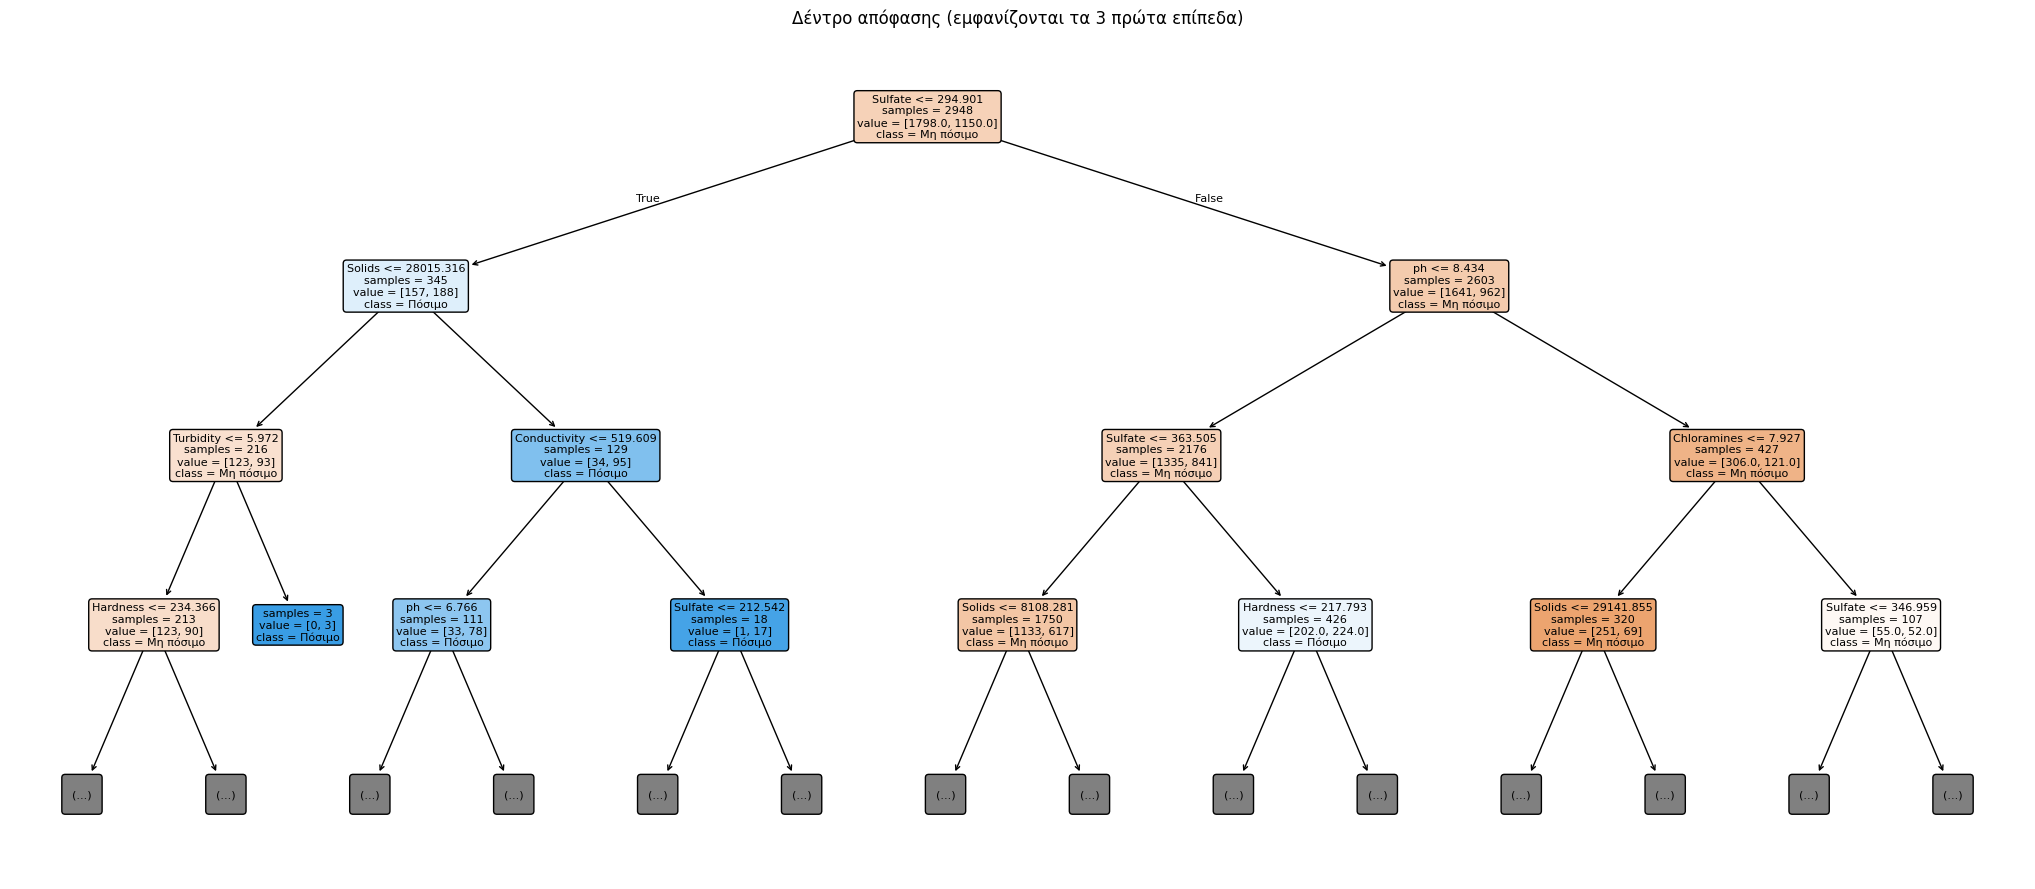

In [62]:
fig, ax = plt.subplots(figsize=(26, 11))
plot_tree(tree5, feature_names=features, class_names=["Μη πόσιμο", "Πόσιμο"],
          filled=True, rounded=True, impurity=False, proportion=False, fontsize=8, max_depth=3, ax=ax)
plt.title("Δέντρο απόφασης (εμφανίζονται τα 3 πρώτα επίπεδα)")
plt.show()

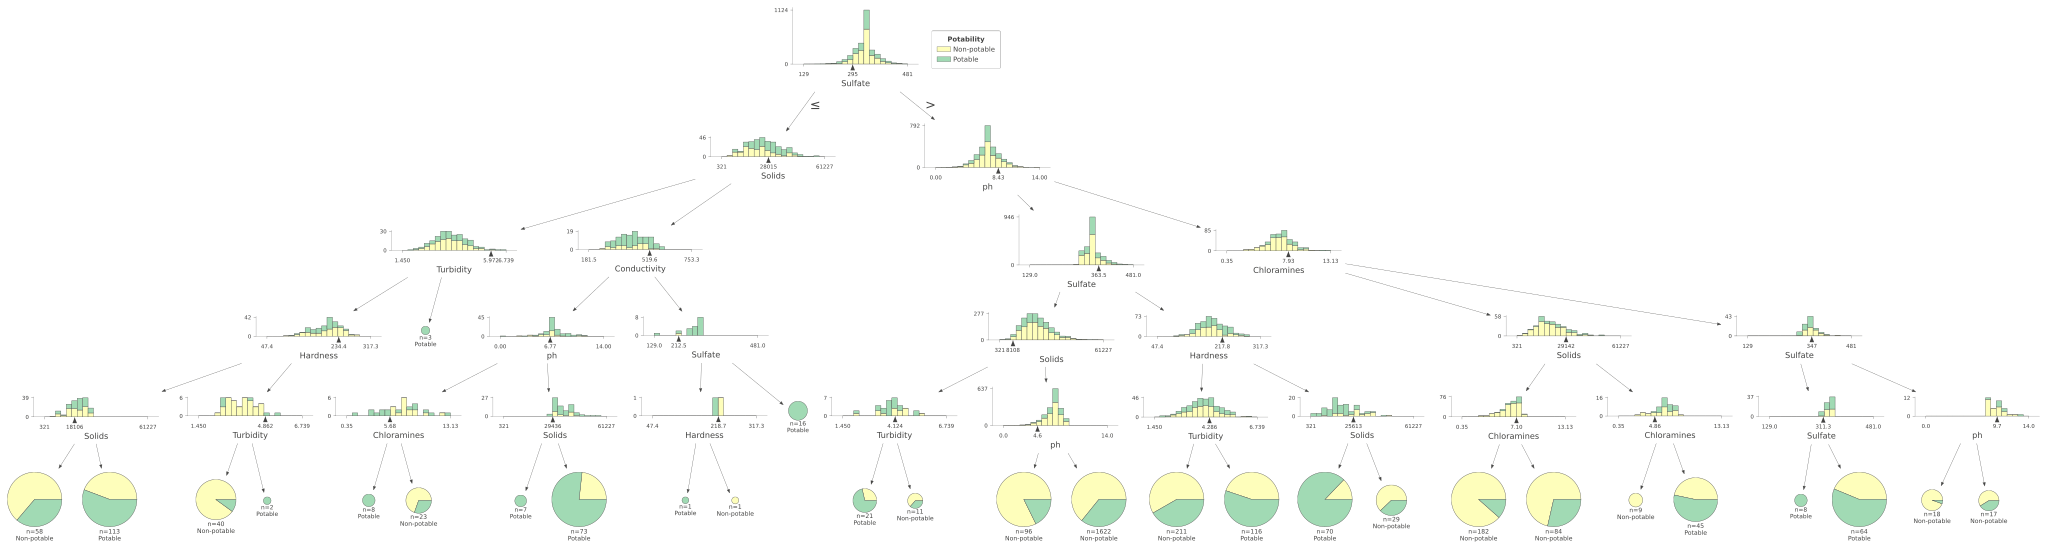

In [63]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
from dtreeviz import model as dtreeviz_model

viz = dtreeviz_model(tree5, X_train, y_train,
                     target_name="Potability",
                     feature_names=features,
                     class_names=["Non-potable", "Potable"])
viz.view(fontname="DejaVu Sans")   # το default "Arial" δεν υπάρχει στο Colab και προκαλεί warnings

In [64]:
from sklearn.tree import export_text
print(export_text(tree5, feature_names=features, max_depth=3))

|--- Sulfate <= 294.90
|   |--- Solids <= 28015.32
|   |   |--- Turbidity <= 5.97
|   |   |   |--- Hardness <= 234.37
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Hardness >  234.37
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Turbidity >  5.97
|   |   |   |--- class: 1
|   |--- Solids >  28015.32
|   |   |--- Conductivity <= 519.61
|   |   |   |--- ph <= 6.77
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- ph >  6.77
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Conductivity >  519.61
|   |   |   |--- Sulfate <= 212.54
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Sulfate >  212.54
|   |   |   |   |--- class: 1
|--- Sulfate >  294.90
|   |--- ph <= 8.43
|   |   |--- Sulfate <= 363.50
|   |   |   |--- Solids <= 8108.28
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Solids >  8108.28
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Sulfate >  363.50
|   |   |   |--

Κανόνες που εξήγαγε το δέντρο (σε παρένθεση πόσα δείγματα του train [μη πόσιμο, πόσιμο] καταλήγουν στο φύλλο):

1. Ρίζα: Sulfate ≤ 294.9. Το δέντρο χωρίζει πρώτα με βάση τα θειικά. Όταν είναι χαμηλά, τα περισσότερα φύλλα προβλέπουν πόσιμο (π.χ. Solids > 28015, Conductivity > 519.6, Sulfate > 212.5 → πόσιμο [0, 16]· ή Solids > 28015, Conductivity ≤ 519.6, pH > 6.77 → πόσιμο [17, 56]). Η ομάδα αυτή είναι μικρή.
2. Sulfate > 294.9 και pH ≤ 8.43: ο μεγαλύτερος κλάδος. Το φύλλο με τα περισσότερα δείγματα είναι Sulfate ≤ 363.5, Solids > 8108, pH > 4.59 → μη πόσιμο με [1041, 581], δηλαδή 1622 δείγματα (55% του train) και μόνο 36% πόσιμα. Είναι η «προεπιλεγμένη» απάντηση του δέντρου.
3. Sulfate > 294.9 και pH > 8.43 (αλκαλικό νερό): κυρίως μη πόσιμο, όπως Chloramines ≤ 7.93, Solids ≤ 29142 → μη πόσιμο [221, 45] και Chloramines > 7.93, Sulfate > 347 → μη πόσιμο. Εξαίρεση είναι Chloramines > 7.93 και Sulfate ≤ 347 → πόσιμο.
4. Τα υπόλοιπα φύλλα (Hardness, Turbidity, Solids σε διάφορα thresholds) είναι μικρά και σχεδόν μισομισά (π.χ. [123, 88]), δηλαδή το δέντρο δεν είναι βέβαιο.

Οι κανόνες είναι σύμφωνοι με τη χημική λογική μόνο μερικώς (π.χ. βασικό νερό → μη πόσιμο), αλλά κανένα φύλλο δεν είναι «καθαρό» εκτός από πολύ μικρά. Γι' αυτό η accuracy παραμένει ~62%.

## Ερώτημα 9 – Πρόβλεψη τυχαίου παραδείγματος και μονοπάτι στο δέντρο

In [65]:
rng = np.random.default_rng(SEED)
i = rng.integers(len(X_test))
x_i = X_test[i].reshape(1, -1)

pred = tree5.predict(x_i)[0]
proba = tree5.predict_proba(x_i)[0]
print("Τιμές του παραδείγματος:")
print(pd.Series(X_test[i], index=features).round(3).to_string())
print()
print("Πρόβλεψη:", "ΠΟΣΙΜΟ" if pred == 1 else "ΜΗ ΠΟΣΙΜΟ", "| πιθανότητες [μη πόσιμο, πόσιμο] =", proba.round(3))
print("Πραγματική κατηγορία:", "ΠΟΣΙΜΟ" if y_test[i] == 1 else "ΜΗ ΠΟΣΙΜΟ")
print()

t = tree5.tree_
path = tree5.decision_path(x_i).indices
print("Μονοπάτι στο δέντρο:")
for node in path:
    if t.children_left[node] == t.children_right[node]:
        cls = t.value[node][0].argmax()
        print(f"  -> Φύλλο #{node}: κλάση = {'Πόσιμο' if cls == 1 else 'Μη πόσιμο'} (δείγματα στο φύλλο: {int(t.n_node_samples[node])})")
    else:
        f, thr = features[t.feature[node]], t.threshold[node]
        val = x_i[0, t.feature[node]]
        sign = "<=" if val <= thr else ">"
        print(f"  Κόμβος #{node}: {f} = {val:.3f} {sign} {thr:.3f}")

Τιμές του παραδείγματος:
ph                    6.150
Hardness            188.413
Solids             8406.723
Chloramines           7.745
Sulfate             358.592
Conductivity        449.359
Organic_carbon       13.220
Trihalomethanes      52.957
Turbidity             3.444

Πρόβλεψη: ΜΗ ΠΟΣΙΜΟ | πιθανότητες [μη πόσιμο, πόσιμο] = [0.642 0.358]
Πραγματική κατηγορία: ΠΟΣΙΜΟ

Μονοπάτι στο δέντρο:
  Κόμβος #0: Sulfate = 358.592 > 294.901
  Κόμβος #24: ph = 6.150 <= 8.434
  Κόμβος #25: Sulfate = 358.592 <= 363.505
  Κόμβος #26: Solids = 8406.723 > 8108.281
  Κόμβος #30: ph = 6.150 > 4.595
  -> Φύλλο #32: κλάση = Μη πόσιμο (δείγματα στο φύλλο: 1622)


Το δείγμα ακολουθεί το μονοπάτι: Sulfate > 294.9 → pH ≤ 8.43 → Sulfate ≤ 363.5 → Solids > 8108 → pH > 4.59 → φύλλο με 1622 δείγματα και πρόβλεψη μη πόσιμο (πιθανότητα 64%). Στο συγκεκριμένο παράδειγμα το δέντρο έκανε λάθος (το νερό ήταν πόσιμο). Δεν προκαλεί έκπληξη: το φύλλο αυτό περιέχει και 36% πόσιμα δείγματα, και το δέντρο δεν μπορεί να τα ξεχωρίσει.

## Ερώτημα 10 – Feature importance και επιλογή 5 αναλύσεων

Συνδυασμός με τη μεγαλύτερη test accuracy:
criterion                gini
max_depth                None
min_samples_split           2
min_samples_leaf            1
max_features             None
ccp_alpha                 0.0
cv_acc               0.581739
test_acc             0.628049


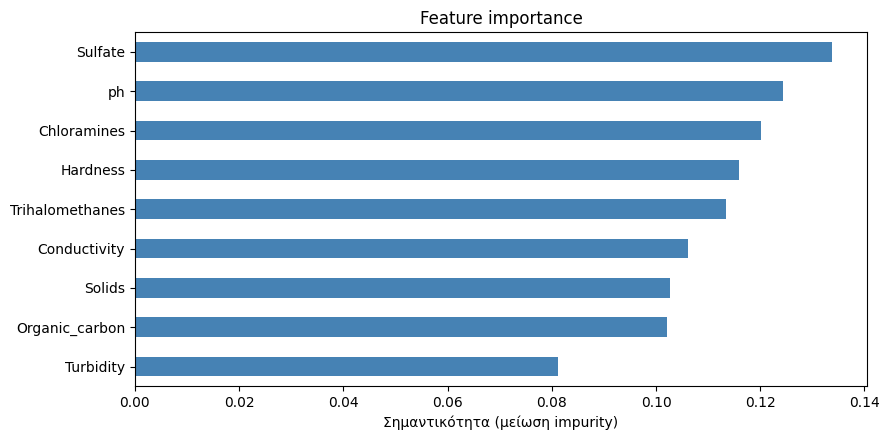

Top-5 χαρακτηριστικά: Sulfate, ph, Chloramines, Hardness, Trihalomethanes
Συνολική σημαντικότητα των top-5: 60.8%


,importance
Sulfate,0.134
ph,0.124
Chloramines,0.120
Hardness,0.116
Trihalomethanes,0.113
Conductivity,0.106
Solids,0.103
Organic_carbon,0.102
Turbidity,0.081


In [66]:
best_all = results.sort_values(["test_acc", "cv_acc"], ascending=False).iloc[0]
print("Συνδυασμός με τη μεγαλύτερη test accuracy:")
print(best_all[cols].to_string())

tree_best = build(best_all).fit(X_train, y_train)
imp = pd.Series(tree_best.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(9, 4.5))
imp.sort_values().plot.barh(color="steelblue")
plt.xlabel("Σημαντικότητα (μείωση impurity)")
plt.title("Feature importance")
plt.tight_layout()
plt.show()

top5 = imp.head(5)
print("Top-5 χαρακτηριστικά:", ", ".join(top5.index))
print("Συνολική σημαντικότητα των top-5: %.1f%%" % (100 * top5.sum()))
imp.round(3).to_frame("importance")

Το δέντρο με τη μεγαλύτερη test accuracy είναι το πλήρες, χωρίς περιορισμούς (max_depth=None, train accuracy 100%). Επειδή έχει εκατοντάδες splits, οι σημαντικότητες βγαίνουν σχεδόν ίσες (0.08–0.13) και το ranking δεν έχει ουσιαστική διακριτική ικανότητα. Το πλήρες δέντρο χρησιμοποιεί κάθε χαρακτηριστικό για να «απομνημονεύσει» θόρυβο.

Για έλεγχο, παραθέτουμε και τις σημαντικότητες του δέντρου που επιλέγεται με cross-validation (max_depth=3):

In [67]:
# Έλεγχος σταθερότητας: feature importance του δέντρου που επιλέγεται με cross-validation
best_cv_row = results.sort_values("cv_acc", ascending=False).iloc[0]
tree_cv = build(best_cv_row).fit(X_train, y_train)
pd.DataFrame({"test-best": tree_best.feature_importances_,
              "cv-best":   tree_cv.feature_importances_}, index=features).round(3)

,test-best,cv-best
ph,0.124,0.413
Hardness,0.116,0.065
Solids,0.103,0.130
Chloramines,0.120,0.064
Sulfate,0.134,0.327
Conductivity,0.106,0.000
Organic_carbon,0.102,0.000
Trihalomethanes,0.113,0.000
Turbidity,0.081,0.000


Στο ρηχό δέντρο το βάρος συγκεντρώνεται στα ph (0.41), Sulfate (0.33), Solids (0.13), Hardness και Chloramines, ενώ τα Conductivity, Organic_carbon, Trihalomethanes, Turbidity δεν χρησιμοποιούνται καθόλου.

Πρόταση για τις 5 αναλύσεις της συσκευής: ph, Sulfate, Solids, Hardness, Chloramines. Αιτιολόγηση:
- Τα ph, Sulfate, Hardness και Chloramines βρίσκονται στο top-5 και των δύο δέντρων. Το Solids είναι 3ο στο cv-best δέντρο και ισοδύναμο με τα υπόλοιπα στο πλήρες.
- Τα ph και Chloramines έχουν και θεσμοθετημένα όρια από τον ΠΟΥ, άρα έχουν νόημα και για τον χρήστη της συσκευής.
- Τα Turbidity (τελευταίο σε σημαντικότητα και στα δύο) και Conductivity/Organic_carbon/Trihalomethanes (μηδενική σημασία στο ρηχό δέντρο) μπορούν να παραλειφθούν.

Επιφύλαξη: η συνολική προβλεπτική ισχύς είναι χαμηλή, και η επιλογή αυτή δεν θα βελτιώσει σημαντικά το μοντέλο· απλώς δεν χάνουμε κάτι ουσιαστικό αφαιρώντας τα υπόλοιπα.

## Ερώτημα 11 – Τι είναι πιο σημαντικό: πόσιμο ή μη πόσιμο;

In [68]:
y_pred = tree5.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(pd.DataFrame(cm, index=["Πραγματικό: μη πόσιμο", "Πραγματικό: πόσιμο"],
                   columns=["Πρόβλεψη: μη πόσιμο", "Πρόβλεψη: πόσιμο"]))
print()
print(classification_report(y_test, y_pred, target_names=["Μη πόσιμο", "Πόσιμο"], zero_division=0))

print("Precision πόσιμου (αξιοπιστία όταν λέει «πόσιμο»): %.3f" % (tp / (tp + fp)))
print("Specificity (μη πόσιμο που αναγνωρίστηκε σωστά):    %.3f" % (tn / (tn + fp)))
print("Recall πόσιμου:                                      %.3f" % (tp / (tp + fn)))
print("F0.5 πόσιμου (δίνει διπλό βάρος στην precision):     %.3f" % fbeta_score(y_test, y_pred, beta=0.5, pos_label=1))
print("Baseline (πάντα «μη πόσιμο»): accuracy = %.3f" % (1 - y_test.mean()))

                       Πρόβλεψη: μη πόσιμο  Πρόβλεψη: πόσιμο
Πραγματικό: μη πόσιμο                  180                20
Πραγματικό: πόσιμο                     104                24

              precision    recall  f1-score   support

   Μη πόσιμο       0.63      0.90      0.74       200
      Πόσιμο       0.55      0.19      0.28       128

    accuracy                           0.62       328
   macro avg       0.59      0.54      0.51       328
weighted avg       0.60      0.62      0.56       328

Precision πόσιμου (αξιοπιστία όταν λέει «πόσιμο»): 0.545
Specificity (μη πόσιμο που αναγνωρίστηκε σωστά):    0.900
Recall πόσιμου:                                      0.188
F0.5 πόσιμου (δίνει διπλό βάρος στην precision):     0.395
Baseline (πάντα «μη πόσιμο»): accuracy = 0.610


In [69]:
rows = []
for name, m in [("Δέντρο ερωτ. 8 (max_depth=5)", tree5), ("Δέντρο ερωτ. 6 (default)", tree)]:
    p = m.predict(X_test)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    rows.append({"Μοντέλο": name, "Accuracy": accuracy_score(y_test, p),
                 "Precision (πόσιμο)": precision_score(y_test, p, zero_division=0),
                 "Specificity": tn_ / (tn_ + fp_), "Recall (πόσιμο)": recall_score(y_test, p),
                 "FP (επικίνδυνα)": fp_, "FN": fn_})
pd.DataFrame(rows).set_index("Μοντέλο").round(3)

,Accuracy,Precision (πόσιμο),Specificity,Recall (πόσιμο),FP (επικίνδυνα),FN
Μοντέλο,,,,,,
Δέντρο ερωτ. 8 (max_depth=5),0.622,0.545,0.900,0.188,20,104
Δέντρο ερωτ. 6 (default),0.628,0.522,0.675,0.555,65,57


Ποιο λάθος είναι χειρότερο; Για συσκευή που ελέγχει αν το νερό πίνεται, το χειρότερο λάθος είναι να χαρακτηρίσει ως πόσιμο νερό που δεν είναι (ψευδώς θετικό): ο χρήστης μπορεί να αρρωστήσει. Το αντίστροφο λάθος (να απορρίψει πόσιμο νερό) είναι μόνο ενοχλητικό ή κοστίζει ένα επιπλέον τεστ. Άρα έχει μεγαλύτερη σημασία να προβλέπει σωστά το μη πόσιμο και, όταν λέει «πόσιμο», να είναι αξιόπιστο.

Κατάλληλες μετρικές: η precision της κλάσης «πόσιμο» (από όσα δηλώνει πόσιμα, πόσα είναι πράγματι), η specificity (πόσα μη πόσιμα αναγνωρίζει) και, ως συνοπτική μετρική, το F0.5 που δίνει διπλό βάρος στην precision. Η accuracy δεν αρκεί, γιατί λόγω της ανισορροπίας κλάσεων (61/39) ένα άχρηστο μοντέλο παίρνει ήδη ~61%.

Αξιολόγηση του δέντρου του ερωτήματος 8:
- Specificity = 0.90: αναγνωρίζει σωστά 180 από τα 200 μη πόσιμα δείγματα. Αυτό φαίνεται καλό, αλλά οφείλεται στο ότι προβλέπει «μη πόσιμο» σχεδόν πάντα (recall πόσιμου μόλις 0.19).
- Precision πόσιμου = 0.545: όταν το δέντρο λέει «πόσιμο» (44 φορές), στις 20 το νερό δεν ήταν πόσιμο, δηλαδή το 45% των «πόσιμων» αποφάσεων είναι επικίνδυνες.
- Accuracy 62.2% ≈ baseline 61%, με F0.5 μόλις 0.40.

Συμπέρασμα: το δέντρο δεν είναι ασφαλές για πραγματική χρήση. Αν και ρηχό δέντρο μειώνει τα ψευδώς θετικά σε σχέση με το πλήρες δέντρο (20 έναντι 65), αυτό γίνεται απλώς προβλέποντας σχεδόν πάντα «μη πόσιμο», και όχι επειδή έχει μάθει να ξεχωρίζει. Για πραγματικό προϊόν θα χρειαζόταν πιο ισχυρό μοντέλο (π.χ. Random Forest), περισσότερα/καλύτερα χαρακτηριστικά, και ρύθμιση του κατωφλίου απόφασης (ή class_weight) ώστε να ελαχιστοποιούνται τα ψευδώς θετικά.